# TP4 - Background Substraction
ATRIM - Option Datasim

Ecole Centrale Nantes

Diana Mateus

Participants: (FILL IN YOUR NAMES AND LASTNAMES)

## BACKGROUND SUBSTRACTION

The goal of this TP is to enhance the video of a neurointervention  to improve the visualization of moving tools. To this end you will implement a pipeline of image processing methods to detect the moving tools automatically.

-------

### Methodology

As the brain is mostly static one way to detect the moving tools is to substract the background (first image) from each of the subsequent images. However, the results of this step need to be further improved. To this end, you will design a pipilene with the methods learnt in this course to produce a binary mask for the pixels that belong to the tools.

In your pipeline use at least:
- one histogram transformation
- one morphological operation
- one filtering operation in the spatial domain
- one filtering operation in the spectral domain
- one segmentation method

_The same pipeline should be applied to every image!!!!!_

-------

### Expected output

The output of your image processing pipeline should be one binary image mask (with values 0 or 1) for every input image of the sequence, where
- the zero valued pixels indicate the moving tools inside each image.  
- the pixels with value 1 indicate the background (not a moving tool)

To validate the proposed method, a human has annotated (manually drawn) the tools of interest within the images. The annotated pixels belong either to catheters or guidewires. **Your masks should be as close as possible to the human annotations.**

-------

### Visualization of data and manual annotations

- Data visualization  (**do not include in final version**): visualize the neurointervention images in the ``` catheter``` folder with name ```frame_#```

- Individual Annotation visualization  (** do not include in final version**): visualize the manual annotations in the ```catheter``` folder with names ``` #_MicroCath``` and ```#_GuideWire```.

- Joint annotation visualization  (** do not include in final version**): visualize the full manual annotation (union of the guidewire and microcatheter masks) by composing the union of the ``` #_MicroCath``` and ```#_GuideWire```. It should also be a binary mask. Dilate the mask to account for manual error
    ```
    selem = disk(2)
    gt_mask = dilation(gt_mask, selem)
    ```
-------

### Experimental Validation (quantitative and qualitative)

To compare your results and the manual annotations use the mean SAD (Sum of Absolute Differences) and the SNR (Signal to Noise Ratio) errors between your  mask and  the **full** manual mask.

Present the results qualitatively and quantitatively:

- Qualitatively:
     - Show your mask side by side with the manually annotated mask
     - Create an enhanced image suitable for guidance: enhance the contrast of the image and overlay your mask on the green channel of the enhanced image.

- Quantitatively: Compare the estimated mask against the mask generated manually
    - compute and print the SAD (sum of absolute differences) error per image.
    - compute and print the MSE (sum of squared  differences ) error per image.
    - compute and print the PSNR (Peak signal to noise ratio) taking as reference image the manual annotations.
    - plot the errors vs time
    - Then compute and print the mean and standard deviation of each measure (SAD, MSE and PSNR) over the entire sequence.
    
    
Hints:
```
mse = numpy.mean( (img1 - img2) ** 2 )
PIXEL_MAX = 255.0 #or 1.0 or max over the signal of interest
psnr = 20 * math.log10(PIXEL_MAX / math.sqrt(mse))
```
or look at ```skimage.measure``` module

You may use modules such as ```scipy```, ```skimage``` or ``sklearn``(e.g. for clustering with K-means or a Gaussian Mixture Model). Ask me for other external modules.


### REPORT INSTRUCTIONS

#### 1. Intermediate Steps (Code and Description)
Report the results of the intermediate steps (when you add or remove a method from the pipeline):
- provide a text introduction with the idea that you intend to try
- show the implementation of the idea with code
- evaluate the quantitative and qualitative changes  when including, varying, adapting, etc the proposed method
- Discuss the scores or visualization improvements/degradations

#### 2. Final Pipeline (Code and Description)
Provide a detailed description of the best performing pipeline. Comment the code such that it is straightforward to relate the pipeline description to the code. Add your conclusions

- Describe the final retained pipeline
- Give a justification for every step (e.g. supported by experimental intermediate steps or theory).
- Add the **commented** code
- Display the qualitative and quantitative results
- Give your conclusions

<class 'SyntaxError'>: invalid syntax (<ipython-input-1-426ee6b7d7da>, line 1)

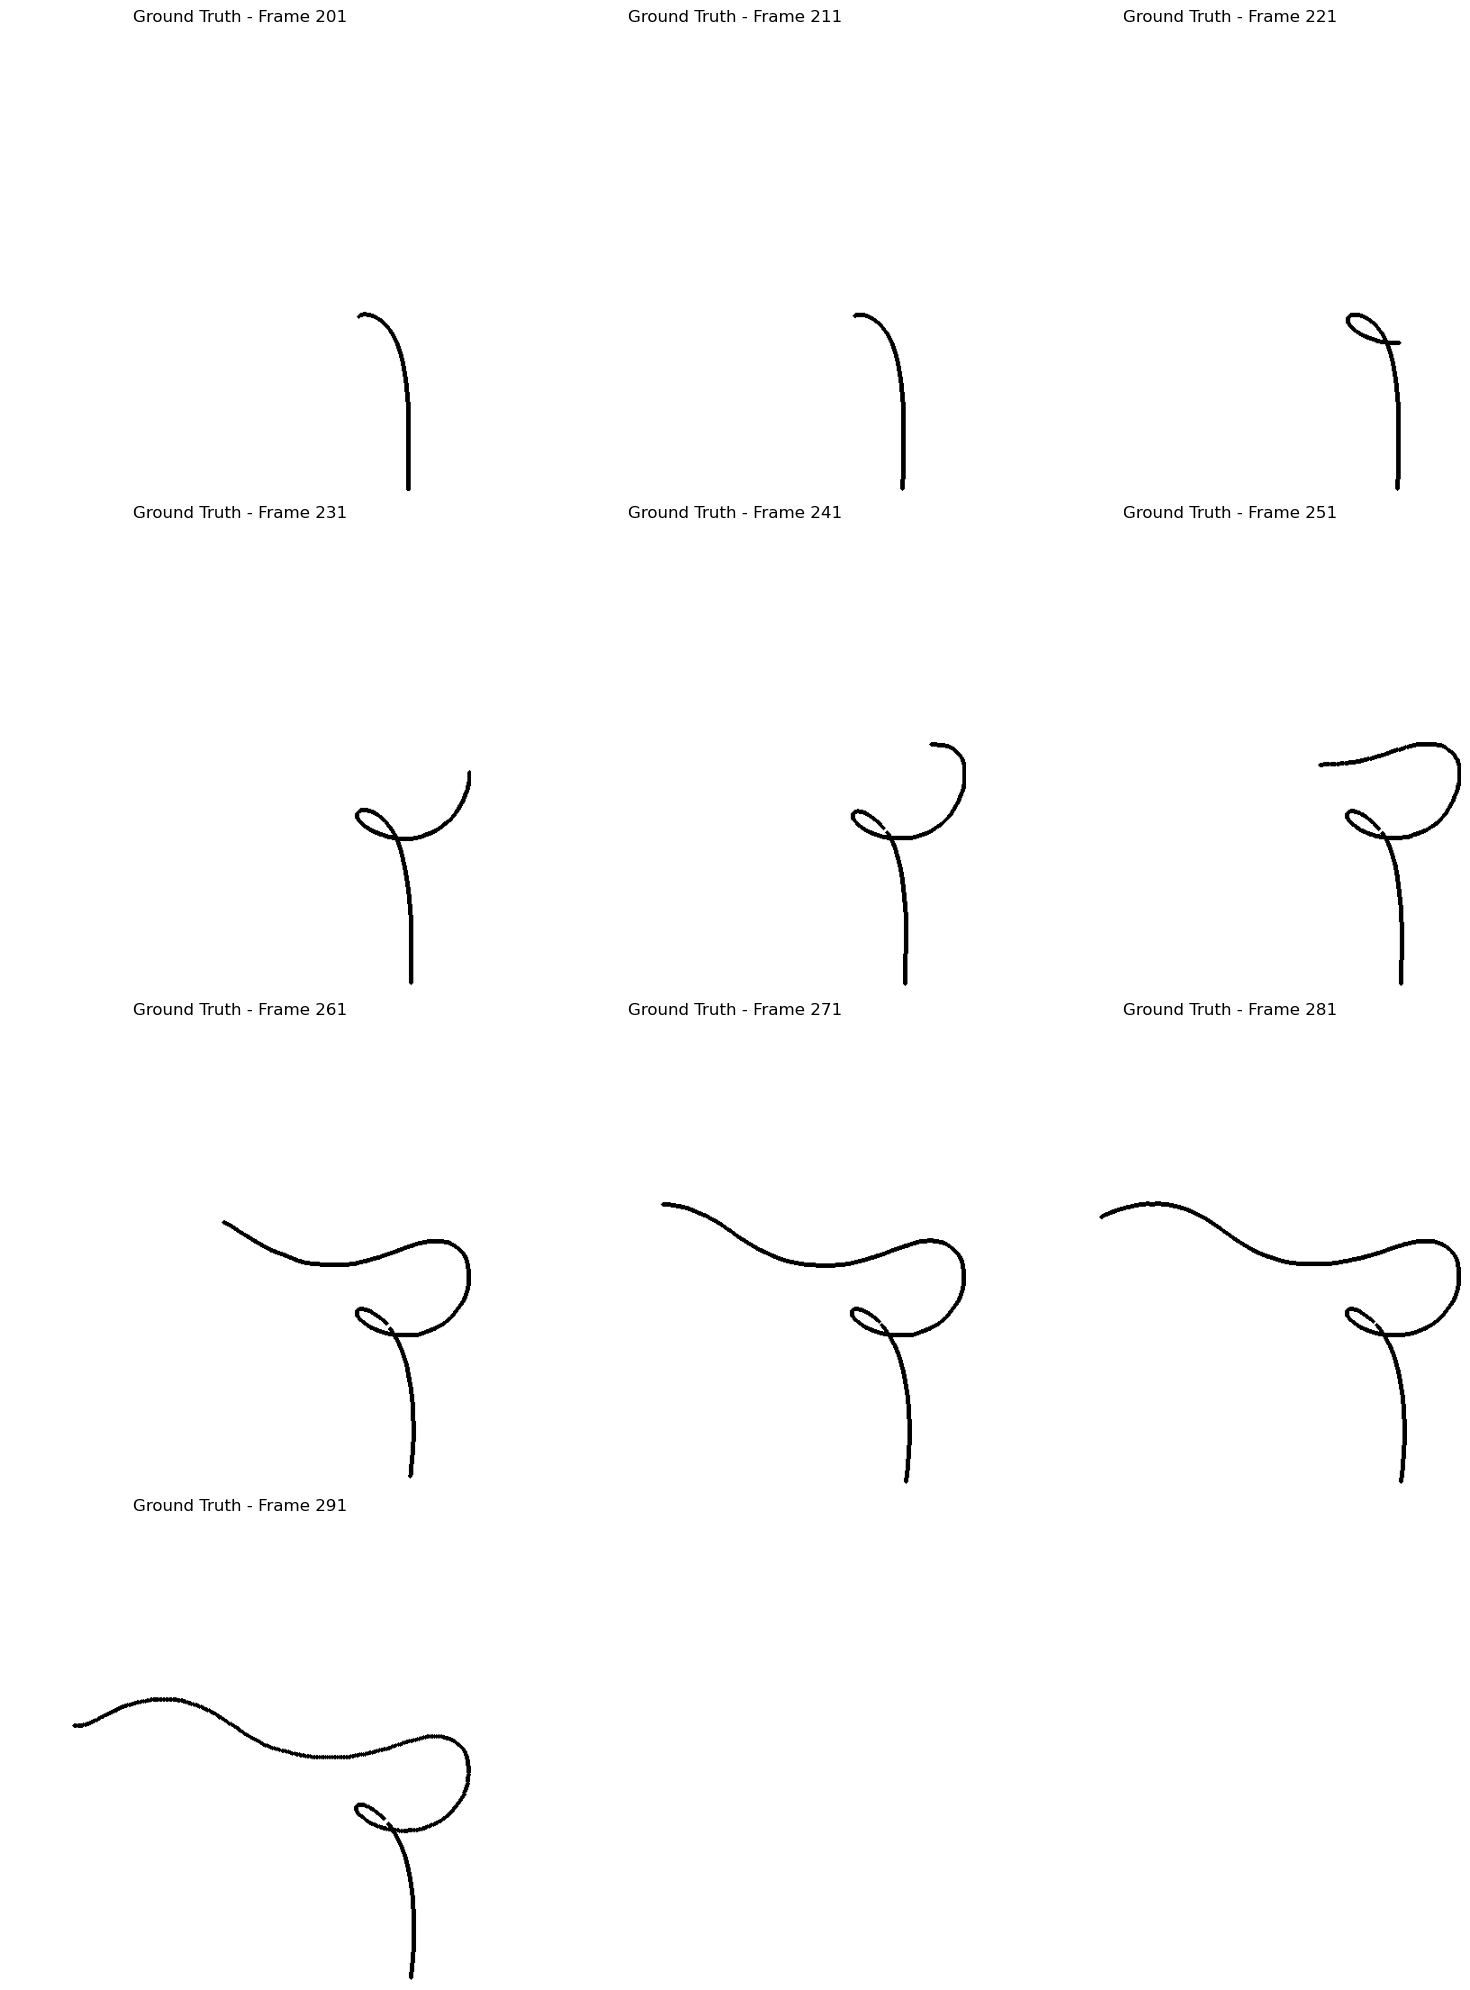

In [17]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.morphology import disk, dilation
from skimage import io

def lire_masque_outil(chemin_fichier):
    # Ouvre l'image et la convertit en niveaux de gris
    img = np.array(Image.open(chemin_fichier).convert('L'))
    # L'outil est noir (< 128) et le fond est blanc (proche de 255)
    # On renvoie True pour l'outil, False pour le fond
    return img < 128

def process_all_ground_truths(folder_path="."):
    all_masks = {}
    microcath_files = glob.glob(os.path.join(folder_path, "*_MicroCath.*"))
    selem = disk(2)
    
    for mc_path in sorted(microcath_files):
        basename = os.path.basename(mc_path)
        frame_id = basename.split('_')[0]
        
        gw_pattern = os.path.join(folder_path, f"{frame_id}_GuideWire.*")
        gw_files = glob.glob(gw_pattern)
        
        if not gw_files:
            continue
            
        gw_path = gw_files[0]
        
        # 1. Isoler les outils (pixels noirs)
        microcath_tool = lire_masque_outil(mc_path)
        guidewire_tool = lire_masque_outil(gw_path)
        
        # 2. Fusionner les deux outils (OU logique)
        combined_tools = np.logical_or(guidewire_tool, microcath_tool)
        
        # 3. Dilater l'outil fusionné
        combined_tools_dilated = dilation(combined_tools, selem)
        
        # 4. Le TP exige : 0 = outil, 1 = fond. 
        # On inverse le masque (~ True devient False) et on convertit en int
        gt_mask_final = (~combined_tools_dilated).astype(np.uint8)
        
        all_masks[frame_id] = gt_mask_final
        
    return all_masks

# --- Exécution et Affichage ---
dossier_images = "catheter" 

masques_finaux = process_all_ground_truths(dossier_images)

# Création d'une grille d'affichage dynamique
nb_images = len(masques_finaux)
if nb_images > 0:
    cols = 3 
    rows = (nb_images + cols - 1) // cols

    plt.figure(figsize=(15, 5 * rows))

    for i, (frame_id, masque) in enumerate(masques_finaux.items(), 1):
        plt.subplot(rows, cols, i)
        # On utilise vmin=0 et vmax=1 pour forcer l'affichage (0=noir, 1=blanc)
        plt.imshow(masque, cmap='gray', vmin=0, vmax=1)
        plt.title(f"Ground Truth - Frame {frame_id}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Aucune image trouvée. Vérifiez le chemin du dossier.")

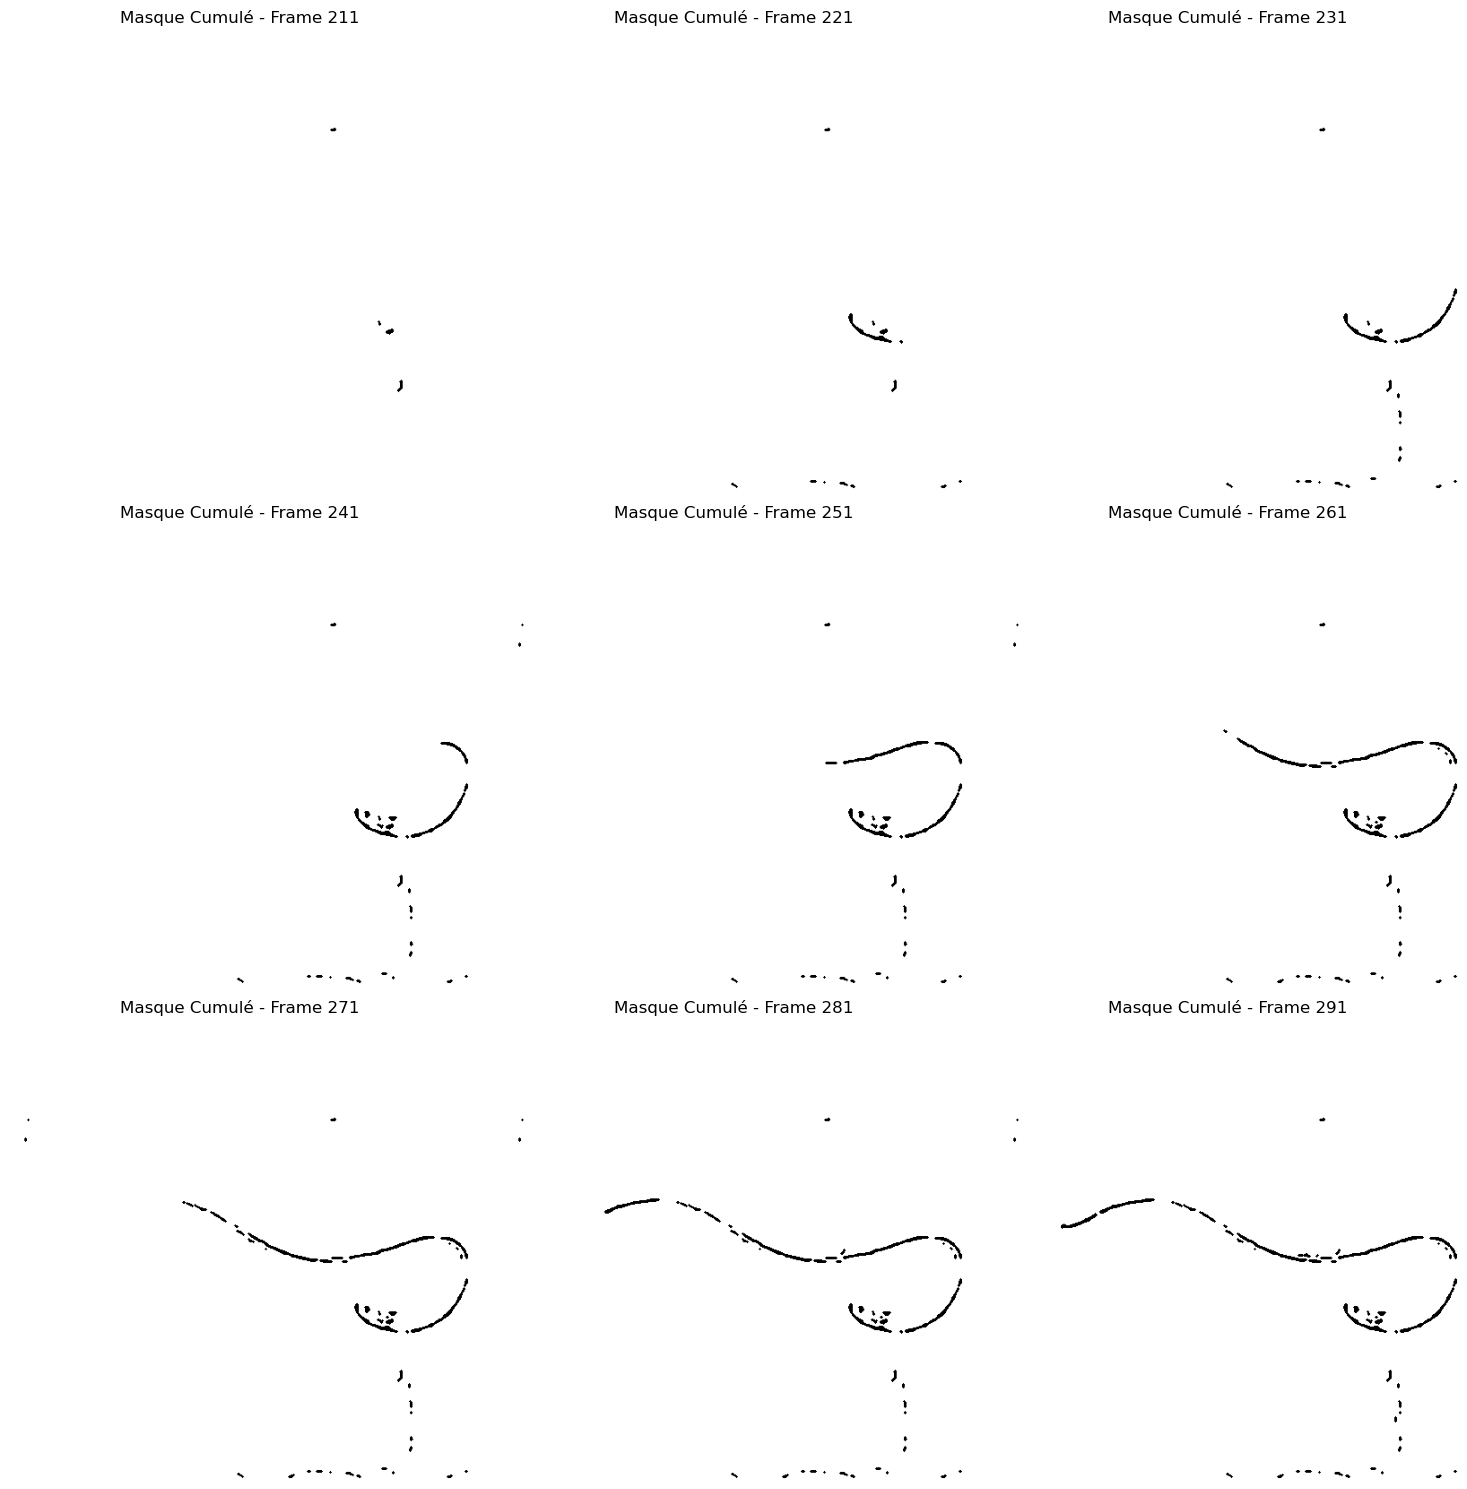

In [18]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def afficher_masques_cumules(dossier_masques="."):
    # Charger tous les masques individuels triés
    fichiers_masques = sorted(glob.glob(os.path.join(dossier_masques, "masque_*.png")))
    
    if not fichiers_masques:
        print("Aucun fichier 'masque_*.png' trouvé. Vérifiez le dossier.")
        return {}

    # Initialiser le masque d'accumulation spatio-temporelle
    premiere_img = np.array(Image.open(fichiers_masques[0]).convert('L'))
    h, w = premiere_img.shape
    cumul_tool = np.zeros((h, w), dtype=bool)

    masques_cumules = {}

    for chemin in fichiers_masques:
        basename = os.path.basename(chemin)
        frame_id = basename.replace("masque_", "").replace(".png", "")

        # Détecter les pixels de l'outil (noir < 128)
        img = np.array(Image.open(chemin).convert('L'))
        tool_instant = (img < 128)

        # Union logique spatio-temporelle : M_t = M_{t-1} U D_t
        cumul_tool = np.logical_or(cumul_tool, tool_instant)

        # Format TP : 0 = outil (noir), 1 = fond (blanc)
        masque_cumul_tp = (~cumul_tool).astype(np.uint8)
        masques_cumules[frame_id] = masque_cumul_tp

    # Affichage dynamique en grille
    nb_images = len(masques_cumules)
    cols = 3
    rows = (nb_images + cols - 1) // cols

    plt.figure(figsize=(15, 5 * rows))

    for i, (frame_id, masque) in enumerate(masques_cumules.items(), 1):
        plt.subplot(rows, cols, i)
        plt.imshow(masque, cmap='gray', vmin=0, vmax=1)
        plt.title(f"Masque Cumulé - Frame {frame_id}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

    return masques_cumules

# Exécution
masques_cumules_dic = afficher_masques_cumules(".")

--- ÉVALUATION : CUMUL DES PRÉDICTIONS VS CUMUL MÉDECIN ---
Frame 211 (Cumulé) | SAD: 1133 | MSE: 0.004322 | PSNR: 23.64 dB
Frame 221 (Cumulé) | SAD: 1347 | MSE: 0.005138 | PSNR: 22.89 dB
Frame 231 (Cumulé) | SAD: 1932 | MSE: 0.007370 | PSNR: 21.33 dB
Frame 241 (Cumulé) | SAD: 2247 | MSE: 0.008572 | PSNR: 20.67 dB
Frame 251 (Cumulé) | SAD: 2575 | MSE: 0.009823 | PSNR: 20.08 dB
Frame 261 (Cumulé) | SAD: 3342 | MSE: 0.012749 | PSNR: 18.95 dB
Frame 271 (Cumulé) | SAD: 3943 | MSE: 0.015041 | PSNR: 18.23 dB
Frame 281 (Cumulé) | SAD: 4179 | MSE: 0.015942 | PSNR: 17.97 dB
Frame 291 (Cumulé) | SAD: 4473 | MSE: 0.017063 | PSNR: 17.68 dB

--- STATISTIQUES GLOBALES SUR LA TRAJECTOIRE CUMULÉE ---
SAD  - Moyenne : 2796.78 | Écart-type : 1169.08
MSE  - Moyenne : 0.010669 | Écart-type : 0.004460
PSNR - Moyenne : 20.16 dB | Écart-type : 2.04 dB


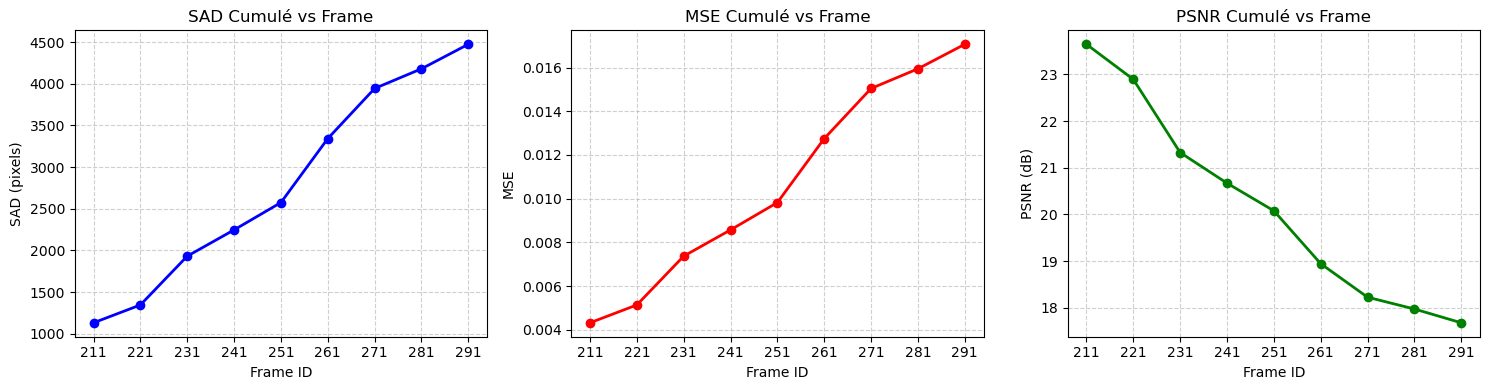

In [19]:
import os
import glob
import math
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def evaluer_cumul_predictions_vs_medecin(masques_gt, dossier_masques="."):
    """
    Calcule et trace les erreurs (SAD, MSE, PSNR) entre le cumul des masques
    estimés et le cumul des annotations manuelles du médecin.
    """
    fichiers_masques = sorted(glob.glob(os.path.join(dossier_masques, "masque_*.png")))
    
    if not fichiers_masques:
        print("Aucun fichier 'masque_*.png' trouvé dans le dossier.")
        return
        
    premiere_img = np.array(Image.open(fichiers_masques[0]).convert('L'))
    h, w = premiere_img.shape
    
    # Masques d'accumulation des outils (True = outil, False = fond)
    cumul_est_tool = np.zeros((h, w), dtype=bool)
    cumul_gt_tool = np.zeros((h, w), dtype=bool)
    
    frames = []
    sad_list = []
    mse_list = []
    psnr_list = []
    
    print("--- ÉVALUATION : CUMUL DES PRÉDICTIONS VS CUMUL MÉDECIN ---")
    
    for chemin in fichiers_masques:
        basename = os.path.basename(chemin)
        frame_id = basename.replace("masque_", "").replace(".png", "")
        
        if frame_id not in masques_gt:
            continue
            
        # 1. Extraction de l'outil prédit à t (0 = outil, 1 = fond)
        img_est = np.array(Image.open(chemin).convert('L'))
        tool_est_t = (img_est < 128)
        
        # 2. Extraction de l'outil médecin (GT) à t (0 = outil, 1 = fond)
        tool_gt_t = (masques_gt[frame_id] == 0)
        
        # 3. Accumulation spatio-temporelle (Union logique)
        cumul_est_tool = np.logical_or(cumul_est_tool, tool_est_t)
        cumul_gt_tool = np.logical_or(cumul_gt_tool, tool_gt_t)
        
        # 4. Conversion au format standard du TP (0 = outil, 1 = fond)
        mask_est_tp = (~cumul_est_tool).astype(float)
        mask_gt_tp = (~cumul_gt_tool).astype(float)
        
        # 5. Calcul des métriques par frame cumulée
        sad = np.sum(np.abs(mask_gt_tp - mask_est_tp))
        mse = np.mean((mask_gt_tp - mask_est_tp) ** 2)
        psnr = 20 * math.log10(1.0 / math.sqrt(mse)) if mse > 0 else float('inf')
        
        frames.append(frame_id)
        sad_list.append(sad)
        mse_list.append(mse)
        psnr_list.append(psnr)
        
        print(f"Frame {frame_id} (Cumulé) | SAD: {sad:.0f} | MSE: {mse:.6f} | PSNR: {psnr:.2f} dB")
        
    # --- BILAN STATISTIQUE ---
    print("\n--- STATISTIQUES GLOBALES SUR LA TRAJECTOIRE CUMULÉE ---")
    print(f"SAD  - Moyenne : {np.mean(sad_list):.2f} | Écart-type : {np.std(sad_list):.2f}")
    print(f"MSE  - Moyenne : {np.mean(mse_list):.6f} | Écart-type : {np.std(mse_list):.6f}")
    print(f"PSNR - Moyenne : {np.mean(psnr_list):.2f} dB | Écart-type : {np.std(psnr_list):.2f} dB")
    
    # --- TRACÉ DES GRAPHIQUES ---
    plt.figure(figsize=(15, 4))
    
    plt.subplot(1, 3, 1)
    plt.plot(frames, sad_list, marker='o', color='blue', linewidth=2)
    plt.title("SAD Cumulé vs Frame")
    plt.xlabel("Frame ID")
    plt.ylabel("SAD (pixels)")
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.subplot(1, 3, 2)
    plt.plot(frames, mse_list, marker='o', color='red', linewidth=2)
    plt.title("MSE Cumulé vs Frame")
    plt.xlabel("Frame ID")
    plt.ylabel("MSE")
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.subplot(1, 3, 3)
    psnr_plot = [p if p != float('inf') else 100 for p in psnr_list]
    plt.plot(frames, psnr_plot, marker='o', color='green', linewidth=2)
    plt.title("PSNR Cumulé vs Frame")
    plt.xlabel("Frame ID")
    plt.ylabel("PSNR (dB)")
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

# Exécution de l'analyse avec vos masques et la vérité terrain chargée
evaluer_cumul_predictions_vs_medecin(masques_finaux, dossier_masques=".")

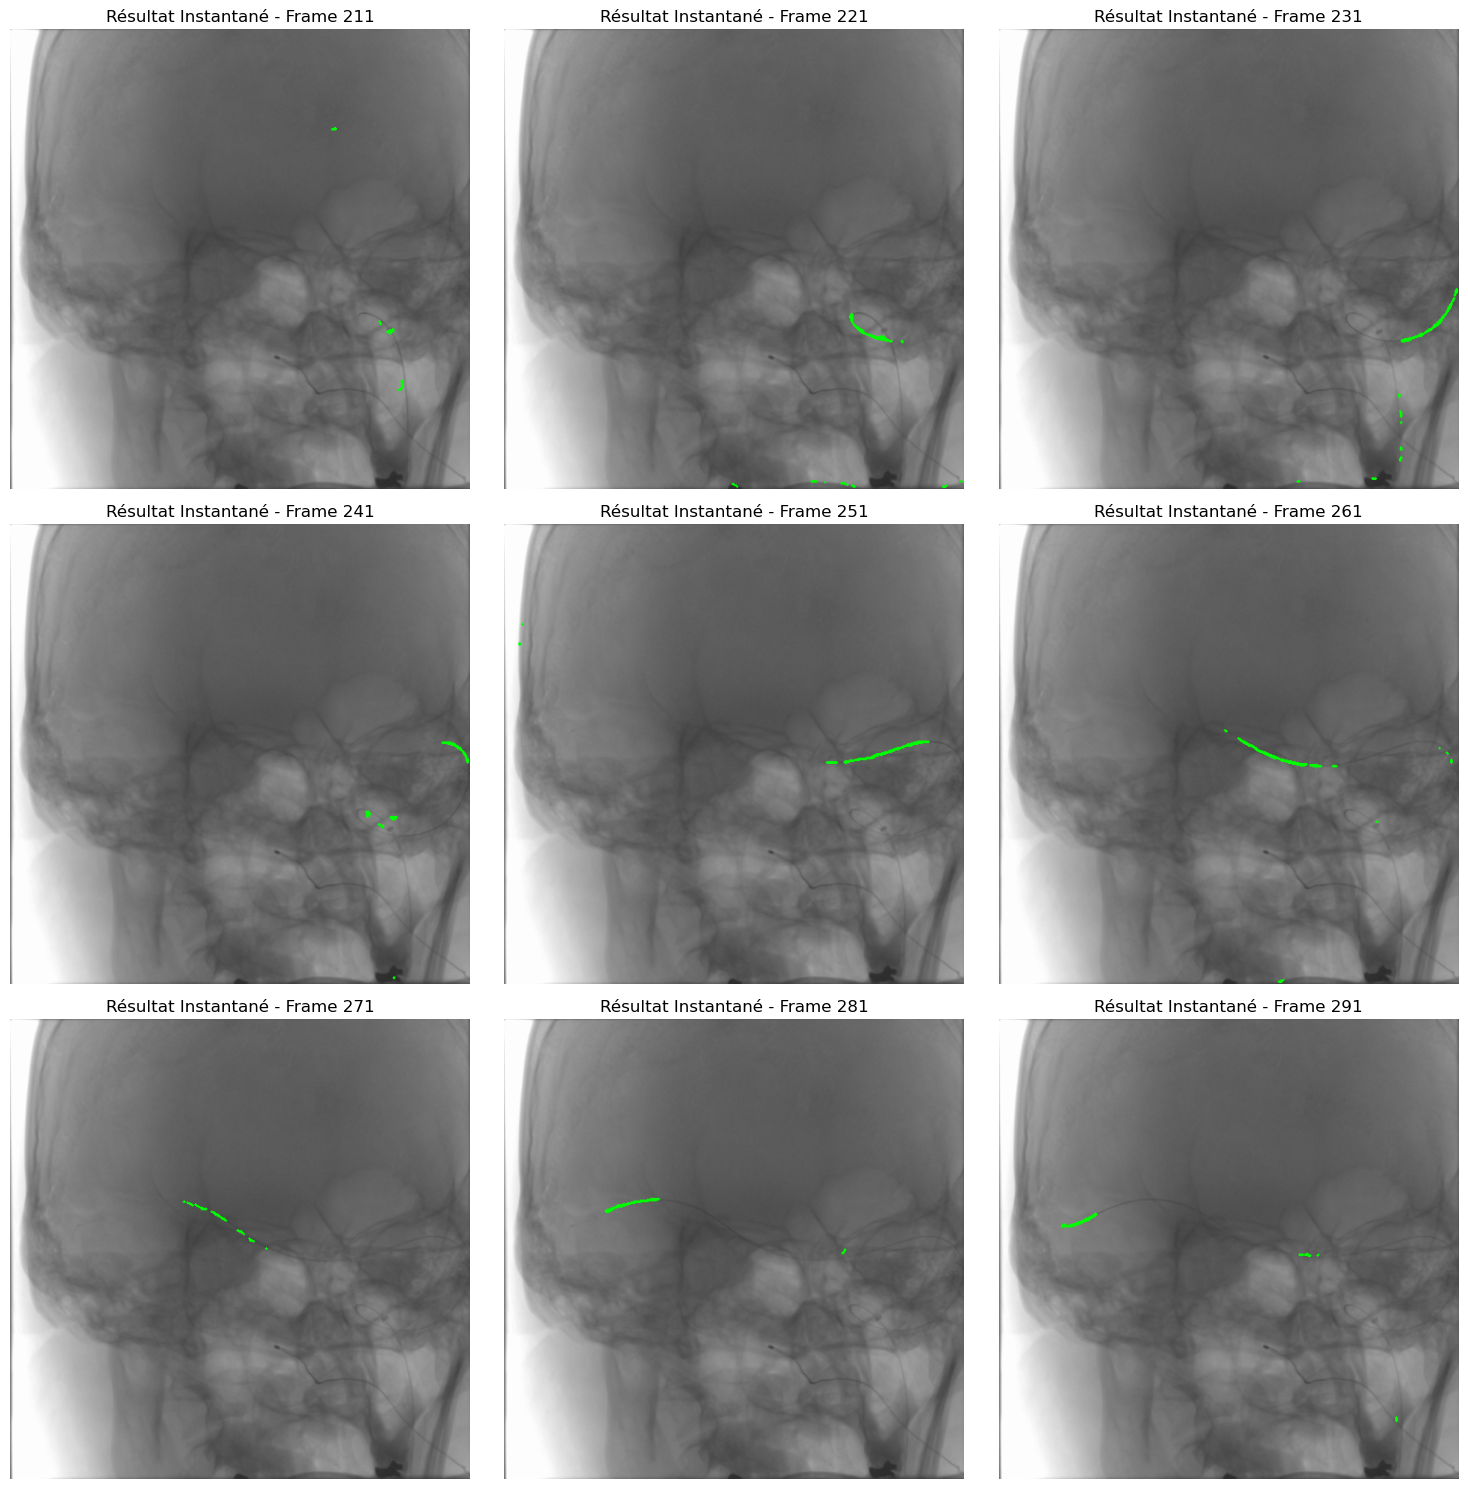

Le GIF des résultats a été créé : sequence_resultats.gif


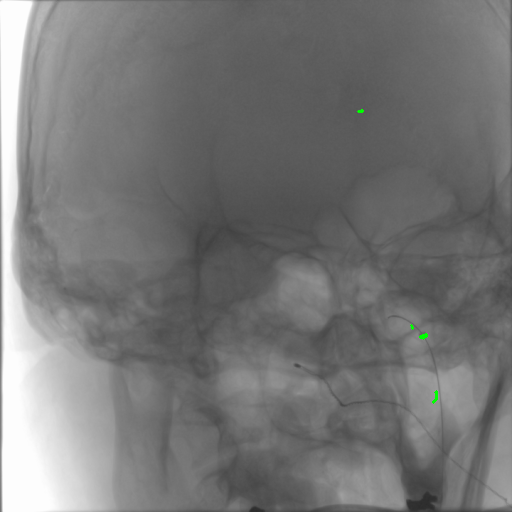

In [20]:
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

def afficher_resultats_instantanes(dossier_resultats="."):
    # Récupérer toutes les images de résultats non cumulées dans l'ordre chronologique
    fichiers = sorted(glob.glob(os.path.join(dossier_resultats, "resultat_*.png")))
    
    if not fichiers:
        print("Aucune image 'resultat_*.png' trouvée. Vérifiez le dossier.")
        return
        
    nb_images = len(fichiers)
    cols = 3
    rows = (nb_images + cols - 1) // cols
    
    plt.figure(figsize=(15, 5 * rows))
    
    for i, chemin in enumerate(fichiers, 1):
        frame_id = os.path.basename(chemin).replace("resultat_", "").replace(".png", "")
        img = Image.open(chemin)
        
        plt.subplot(rows, cols, i)
        plt.imshow(img)
        plt.title(f"Résultat Instantané - Frame {frame_id}")
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()

# Exécution de l'affichage
afficher_resultats_instantanes(".")

import glob
from PIL import Image

# Récupérer toutes les images de résultats dans l'ordre chronologique
fichiers_resultats = sorted(glob.glob("resultat_*.png"))

# Charger les images
images = [Image.open(f).convert("RGB") for f in fichiers_resultats]

if images:
    # Sauvegarde du GIF animé
    images[0].save(
        "sequence_resultats.gif",
        save_all=True,
        append_images=images[1:],
        duration=300,  # Temps d'affichage par image en millisecondes (300 ms = 0.3s)
        loop=0          # 0 = boucle infinie
    )
    print("Le GIF des résultats a été créé : sequence_resultats.gif")
else:
    print("Aucune image 'resultat_*.png' trouvée.")

from IPython.display import Image; Image(filename="sequence_resultats.gif")

Frame 211 traitée et sauvegardée.
Frame 221 traitée et sauvegardée.
Frame 231 traitée et sauvegardée.
Frame 241 traitée et sauvegardée.
Frame 251 traitée et sauvegardée.
Frame 261 traitée et sauvegardée.
Frame 271 traitée et sauvegardée.
Frame 281 traitée et sauvegardée.
Frame 291 traitée et sauvegardée.


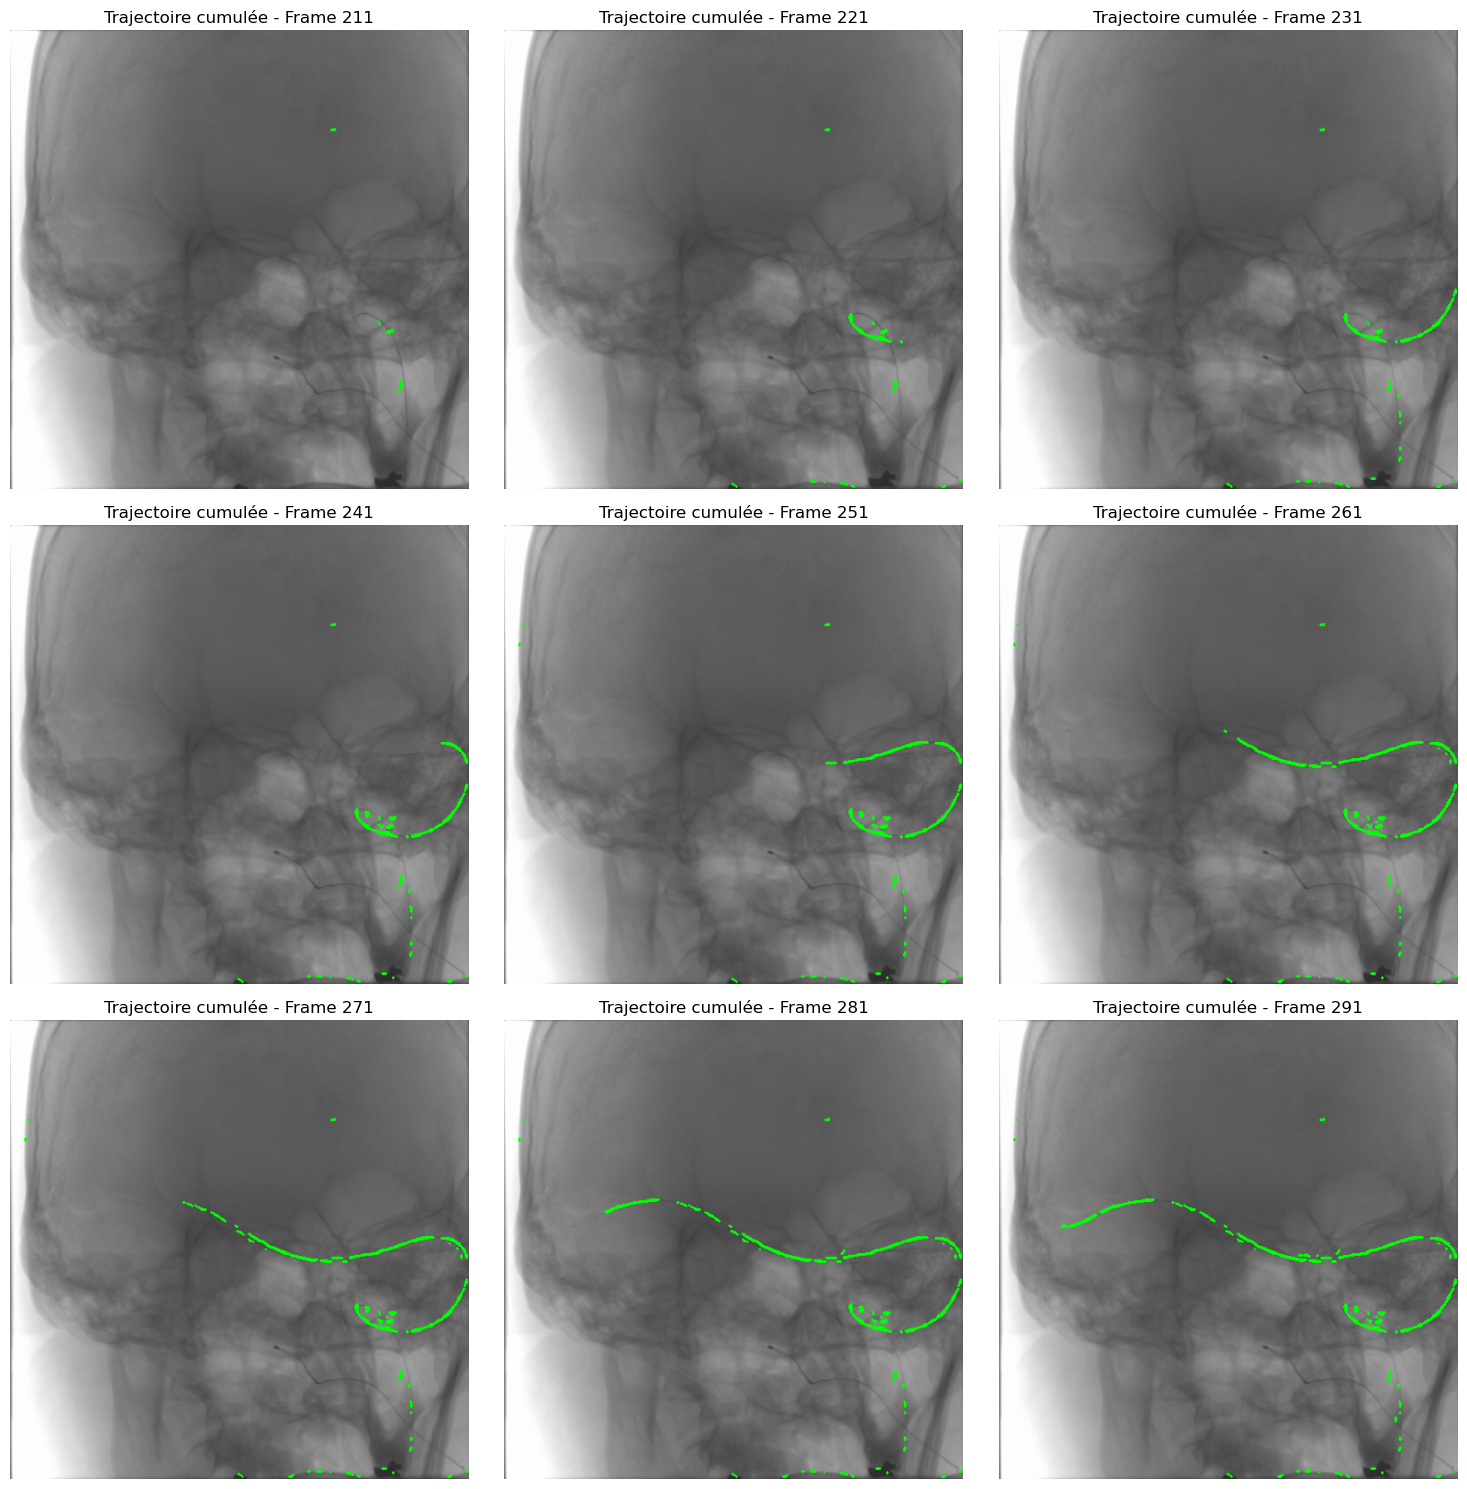

GIF généré avec succès : trajectoire_cumulee.gif


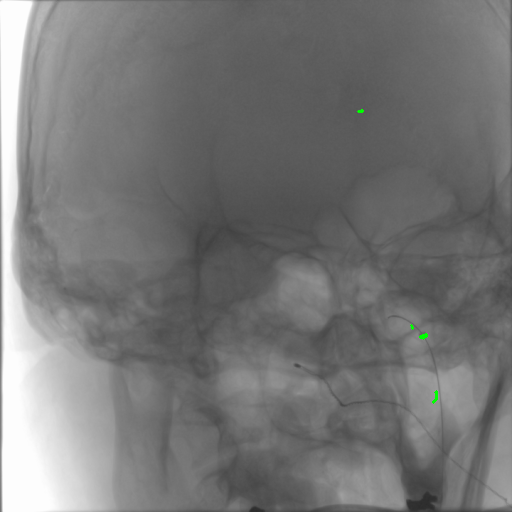

In [21]:
def cumuler_trajectoire_outils(dossier_resultats=".", dossier_sortie="resultats_cumules"):
    """
    Accumule les détections d'outils (pixels verts) des images précédentes
    pour reconstruire la trajectoire complète du fil et du cathéter.
    """
    os.makedirs(dossier_sortie, exist_ok=True)
    
    # Charger la liste triée des résultats
    fichiers = sorted(glob.glob(os.path.join(dossier_resultats, "resultat_*.png")))
    
    if not fichiers:
        print("Aucune image 'resultat_*.png' trouvée.")
        return {}
        
    # Initialiser le masque cumulé (vide au départ)
    premiere_image = io.imread(fichiers[0])
    hauteur, largeur = premiere_image.shape[:2]
    masque_cumule = np.zeros((hauteur, largeur), dtype=bool)
    
    images_cumulees = {}
    
    for chemin in fichiers:
        basename = os.path.basename(chemin)
        frame_id = basename.replace("resultat_", "").replace(".png", "")
        
        img_res = io.imread(chemin)
        
        # 1. Isoler la détection de l'image courante (pixels verts : Canal G > Canal R)
        outil_courant = (img_res[:, :, 1] > img_res[:, :, 0]) & (img_res[:, :, 1] > 30)
        
        # 2. Somme cumulative (OU logique entre le masque passé et le masque présent)
        masque_cumule = np.logical_or(masque_cumule, outil_courant)
        
        # 3. Reconstruire l'image avec la trajectoire complète en vert
        fond_gris = img_res[:, :, 0]  # Récupération de l'image de fond en niveaux de gris
        
        # Créer une image RGB
        img_cumul = np.stack([fond_gris, fond_gris, fond_gris], axis=-1).copy()
        
        # Superposer la trajectoire cumulée en vert vif (R=0, G=255, B=0)
        img_cumul[masque_cumule, 0] = 0
        img_cumul[masque_cumule, 1] = 255
        img_cumul[masque_cumule, 2] = 0
        
        images_cumulees[frame_id] = img_cumul
        
        # Sauvegarde sur le disque
        chemin_sortie = os.path.join(dossier_sortie, f"cumul_{frame_id}.png")
        io.imsave(chemin_sortie, img_cumul)
        print(f"Frame {frame_id} traitée et sauvegardée.")
        
    return images_cumulees

import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Image as IPImage, display

# 1. Exécution de l'accumulation et affichage de la grille d'images
resultats_cumules = cumuler_trajectoire_outils(dossier_resultats=".", dossier_sortie="resultats_cumules")

nb_images = len(resultats_cumules)
if nb_images > 0:
    cols = 3
    rows = (nb_images + cols - 1) // cols
    plt.figure(figsize=(15, 5 * rows))

    for i, (frame_id, img_cumul) in enumerate(resultats_cumules.items(), 1):
        plt.subplot(rows, cols, i)
        plt.imshow(img_cumul)
        plt.title(f"Trajectoire cumulée - Frame {frame_id}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()  # Correction : Ajout des parenthèses ()

# 2. Fonction de génération du GIF avec retour du chemin
def creer_et_afficher_gif_cumule(dossier_cumules="resultats_cumules", duree_ms=300):
    fichiers = sorted(glob.glob(f"{dossier_cumules}/cumul_*.png"))
    
    if not fichiers:
        print(f"Aucune image 'cumul_*.png' trouvée dans le dossier '{dossier_cumules}'.")
        return None
        
    images = [Image.open(f).convert("RGB") for f in fichiers]
    chemin_gif = "trajectoire_cumulee.gif"
    
    images[0].save(
        chemin_gif,
        save_all=True,
        append_images=images[1:],
        duration=duree_ms,
        loop=0
    )
    
    print(f"GIF généré avec succès : {chemin_gif}")
    return chemin_gif

# 3. Génération et affichage du GIF
chemin_obtenu = creer_et_afficher_gif_cumule("resultats_cumules", duree_ms=300)

if chemin_obtenu:
    display(IPImage(filename=chemin_obtenu))